# Del cierre transitivo29 al balance por masa30
El notebook enseña el fallo del conteo de grupos y una DP clásica. Todos los datos son sintéticos; no hay modelo predictivo ni evidencia causal.

## Derivación: unidad de filas, no número de grupos
Sea $C_i$ la componente declarada $i$, $w_i=|C_i|\in\mathbb N$ su tamaño (filas), $N=\sum_{i=1}^K w_i$ (filas). La decisión $x_i\in\{0,1\}$ lleva toda $C_i$ a entrenamiento si $x_i=1$. Objetivo de fracción $r=p/q$ sin unidades, con $0<p<q$ enteros:
$$s=\sum_i w_i x_i,\qquad 0<s<N,\qquad J(x)=|s-rN|\quad[\text{filas}].$$
Multiplicar por $q>0$ preserva el mínimo:
$$\arg\min_x J(x)=\arg\min_x |q s-pN|.$$
El código `best` usa solo enteros; exporta `deviation_rows=abs(q*s-p*N)/q`. No hay tolerancia numérica para el objetivo. Empates numéricos eligen menor masa; un testigo se conserva por orden determinista, sin prometer mínimo lexicográfico entre subconjuntos.

Estados alcanzables tras $i$ componentes:
$$R_0=\{0\},\qquad R_i=R_{i-1}\cup\{s+w_i:s\in R_{i-1}\}.$$
Inducción: cualquier subconjunto excluye $i$ (primer conjunto) o lo incluye una sola vez (segundo); inversamente cada estado tiene testigo factible. `list(witnesses.items())` congela $R_{i-1}$ antes de actualizar: no reutiliza una componente. Minimizar sobre $R_K\setminus\{0,N\}$ da óptimo del objetivo finito, no teorema estadístico ni garantía de generalización.

Sin cortar componentes se conserva el invariante $a(u)=a(v)$ para todo par en una misma componente. No prueba que el grafo sea completo/verdadero. DP con testigos de tuplas: hasta $N+1$ estados y tuplas de longitud $K$; coste conservador $O(K^2N)$ tiempo y $O(KN)$ memoria (sin bits de enteros/strings), además de componentes/ordenación. Guardias2000filas y100componentes limitan alcance, no SLA ni prueba de escalabilidad.

In [1]:
from src.balancing import fixture, balanced_split, count_split
from src.splitter import leaked_components
rows=fixture([1,2,3,10])
for name,fn in [("count",count_split),("exact",balanced_split)]:
    a=fn(rows); s=sum(v=="train" for v in a.values())
    print(name,"train rows",s,"J",abs(s-len(rows)/2),"cuts",leaked_components(rows,a))

count train rows 13 J 5.0 cuts 0
exact train rows 6 J 2.0 cuts 0


## Construyamos los estados a mano
Empezamos sin filas y añadimos cada peso una sola vez. Los estados no alcanzables explican por qué pedir50% exacto puede ser imposible.

In [2]:
reachable={0}
for w in [1,2,3,10]:
    reachable=reachable | {s+w for s in reachable}
    print("weight",w,"reachable",sorted(reachable))
print("best proper mass",min((s for s in reachable if 0<s<16),key=lambda s:(abs(2*s-16),s)))

weight 1 reachable [0, 1]
weight 2 reachable [0, 1, 2, 3]
weight 3 reachable [0, 1, 2, 3, 4, 5, 6]
weight 10 reachable [0, 1, 2, 3, 4, 5, 6, 10, 11, 12, 13, 14, 15, 16]
best proper mass 6


## Sensibilidad al objetivo
Cambiar la fracción cambia la función objetivo, sin cambiar vínculos. No usamos test labels para escoger el mejor split.

In [3]:
for p,q in [(1,4),(1,3),(1,2),(2,3),(3,4)]:
    a=balanced_split(rows,p,q); s=sum(v=="train" for v in a.values())
    print(f"r={p}/{q}: s={s}, J={abs(q*s-p*len(rows))/q:.4f} rows")

r=1/4: s=4, J=0.0000 rows
r=1/3: s=5, J=0.3333 rows
r=1/2: s=6, J=2.0000 rows
r=2/3: s=11, J=0.3333 rows
r=3/4: s=12, J=0.0000 rows


## Negativo que la optimización no soluciona
Con pesos1,1,1,30, las únicas masas propias cercanas a16.5 son3 y30. Por tanto $J^*=13.5$ filas. Cero cortes puede coexistir con test poco útil.

In [4]:
giant=fixture([1,1,1,30]); a=balanced_split(giant)
s=sum(v=="train" for v in a.values())
print("giant:",s,"train,",len(giant)-s,"test, deviation",abs(s-16.5))
try:
    balanced_split(fixture([33]))
except ValueError as error:
    print("one component rejected:",error)

giant: 3 train, 30 test, deviation 13.5
one component rejected: need at least two connected components


In [5]:
import json
from pathlib import Path
summary=json.loads(Path("results/balancing30/summary.json").read_text())
print({k:summary[k] for k in ["comparisons","improved","equal","worse","leaks","mean_deviation"]})
for entry in summary["scale"]:
    print(entry["groups"],entry["policy"],"time_ns",entry["elapsed_ns"],"peak_bytes",entry["peak_bytes"])

{'comparisons': 25, 'improved': 20, 'equal': 5, 'worse': 0, 'leaks': 0, 'mean_deviation': {'count': 3.506666666666667, 'exact': 2.0133333333333336}}
10 count time_ns 244522 peak_bytes 5424
10 exact time_ns 400774 peak_bytes 12352
30 count time_ns 742942 peak_bytes 12048
30 exact time_ns 2174413 peak_bytes 39088
60 count time_ns 1420035 peak_bytes 23968
60 exact time_ns 8246094 peak_bytes 109372


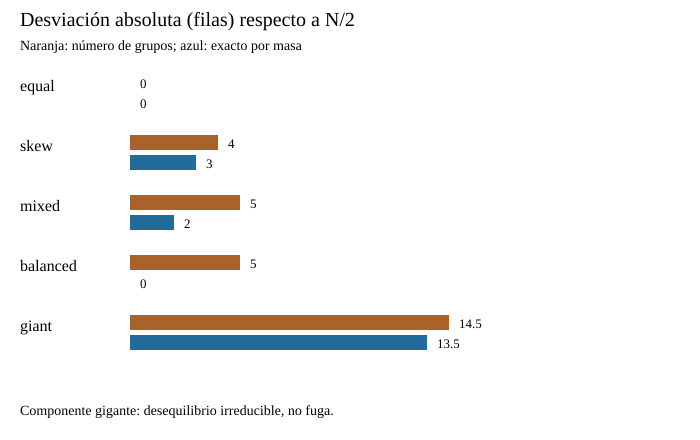

In [6]:
from IPython.display import SVG,display
display(SVG(filename="results/balancing30/balance.svg"))

## Lectura crítica
Menor desviación no garantiza mejor predicción ni equidad. Solo conocemos enlaces declarados. El DP cuesta más que contar grupos y no supera el límite aritmético de una componente gigante. Estado: prototipo local ejecutado; validación real y operacional pendientes. Consulte prior_art30.md, research-log.md y roadmap.md.